# Variables base para las interacciones

`PolynomialFeatures` multiplica de a pares las variables que recibe, así que con unas 280 columnas crearía decenas de miles de combinaciones. Este notebook elige pocas variables base (diez) con dos criterios a la vez: que se parezcan al frío de mañana y que no digan lo mismo entre sí. Todo se mide con la correlación de Spearman (que compara el orden de los valores y no los valores) y solo con el tramo de entrenamiento, nunca con validación ni prueba.

## 1. Preparación: tabla con todas las variables

Se carga la tabla, se divide en entrenamiento, validación y prueba, se limpia con las reglas aprendidas solo en entrenamiento y se le agregan las variables temporales y las razones de planta ya creadas. Todas las decisiones de este notebook se toman únicamente con las filas de entrenamiento.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.cluster.hierarchy import dendrogram, linkage

sys.path.append("../src")
from auxiliar_functions import tabla_simple
from preprocessing_pipeline import cargar_tabla_completa, dividir_por_fecha
from limpieza import aprender_reglas_de_limpieza, limpiar
from variables_temporales import crear_variables_temporales, NOMBRES_NUEVAS as NOMBRES_TEMPORALES
from variables_planta import aprender_reglas_de_planta, crear_variables_planta, NOMBRES_NUEVAS as NOMBRES_PLANTA
from variables_interacciones import (UMBRAL_CORRELACION, CANTIDAD_BASE, COLUMNA_OBJETIVO, columnas_candidatas,
                                     spearman_con_objetivo, matriz_spearman, agrupar_por_correlacion,
                                     elegir_por_grupos, elegir_voraz, aprender_reglas_de_interacciones,
                                     crear_interacciones, nombres_de_interacciones)

tabla_completa = cargar_tabla_completa(Path("../data"))
X_train, X_val, X_test = dividir_por_fecha(tabla_completa)
tabla_limpia = limpiar(tabla_completa, aprender_reglas_de_limpieza(X_train)).copy()
train_limpio, _, _ = dividir_por_fecha(tabla_limpia)
tabla_con_variables = crear_variables_planta(crear_variables_temporales(tabla_limpia),
                                             aprender_reglas_de_planta(train_limpio))
entrenamiento, validacion, prueba = dividir_por_fecha(tabla_con_variables)

control = pd.DataFrame({"Valor": {
    "Días de la tabla": len(tabla_con_variables), "Columnas de la tabla": tabla_con_variables.shape[1],
    "Días de entrenamiento": len(entrenamiento), "Días de validación": len(validacion),
    "Días de prueba": len(prueba)}}).rename_axis("Control").reset_index()
print("Tabla 1. Control de la tabla de partida (con variables temporales y razones de planta)")
display(tabla_simple(control, precision=0))

Tabla 1. Control de la tabla de partida (con variables temporales y razones de planta)


,Control,Valor
0,Días de la tabla,1212
1,Columnas de la tabla,292
2,Días de entrenamiento,848
3,Días de validación,182
4,Días de prueba,182


## 2. Qué variables compiten

No toda columna puede ser variable base. Se dejan afuera las columnas de control (fechas, banderas de validez, el propio consumo del día repetido y el objetivo), el texto y las columnas constantes, porque una columna que no cambia no tiene correlación. La tabla cuenta cuántas candidatas hay según su origen.

In [2]:
candidatas = columnas_candidatas(entrenamiento.drop(columns=[COLUMNA_OBJETIVO]))
origen = ["Variable temporal" if c in NOMBRES_TEMPORALES else "Razón de planta" if c in NOMBRES_PLANTA
          else "Columna original limpia" for c in candidatas]
conteo = pd.Series(origen).value_counts().rename_axis("Origen").reset_index(name="Cantidad")
conteo.loc[len(conteo)] = ["Total de candidatas", len(candidatas)]
print("Tabla 2. Variables candidatas a ser base de las interacciones")
display(tabla_simple(conteo, precision=0))

X = entrenamiento[candidatas].astype(float)               # las booleanas pasan a 0 y 1
objetivo = entrenamiento[COLUMNA_OBJETIVO]

Tabla 2. Variables candidatas a ser base de las interacciones


,Origen,Cantidad
0,Columna original limpia,262
1,Variable temporal,10
2,Razón de planta,6
3,Total de candidatas,278


## 3. Parecido de cada variable con el frío de mañana

Para cada candidata se mide la correlación de Spearman con el frío de mañana usando solo los días de entrenamiento en que ambas tienen valor. Lo que importa es el tamaño del número y no su signo: una variable con parecido negativo también informa, porque sube cuando el objetivo baja. La tabla muestra las quince más parecidas.

In [3]:
parecido = spearman_con_objetivo(X, objetivo)
dias_usados = X.notna().mul(objetivo.notna(), axis=0).sum()
ranking = (pd.DataFrame({"Variable": parecido.index, "Spearman con el frío de mañana": parecido.to_numpy(),
                         "Días usados": dias_usados.to_numpy()})
           .assign(Tamaño=lambda t: t["Spearman con el frío de mañana"].abs())
           .sort_values("Tamaño", ascending=False).drop(columns="Tamaño").head(15))
print("Tabla 3. Las 15 variables más parecidas al frío de mañana (solo entrenamiento)")
display(tabla_simple(ranking, precision=3))

Tabla 3. Las 15 variables más parecidas al frío de mañana (solo entrenamiento)


,Variable,Spearman con el frío de mañana,Días usados
13,Frio (Kw),0.847,817
265,frio_media_7_dias,0.834,829
9,Sala Maq (Kw),0.833,814
8,Servicios (Kw),0.818,817
269,dia_anio_coseno,-0.801,831
18,KW Gral Planta,0.786,816
100,Totalizadores Energia | KW Gral Planta,0.783,829
0,Planta (Kw),0.781,816
262,frio_ayer,0.752,813
263,frio_hace_2_dias,0.731,812


Varias de las más parecidas son del propio frío (el de hoy y su promedio de siete días) o de consumos eléctricos de la misma planta, que suben y bajan juntos. Si se eligieran solo por este ranking, las diez base serían casi la misma información repetida, y las interacciones entre ellas no aportarían nada nuevo. Por eso hace falta medir también cuánto se parecen entre sí.

## 4. Cuánto se parecen entre sí: agrupamiento sobre todas las variables

Se calcula la correlación de Spearman entre todas las candidatas (la matriz completa) y con ella se agrupan las variables que dicen lo mismo. La distancia entre dos variables es uno menos el valor absoluto de su correlación, y el agrupamiento usa el enlace completo: una variable entra a un grupo solo si se parece, con correlación de al menos el umbral, a cada una de las que ya están. Así, dentro de un grupo todos los pares son redundantes. Este cálculo usa todas las candidatas, sin recortar ninguna.

In [4]:
correlaciones = matriz_spearman(X)
grupos, enlace = agrupar_por_correlacion(correlaciones, UMBRAL_CORRELACION)

tamanos = grupos.value_counts()
resumen = pd.DataFrame({"Valor": {
    "Variables agrupadas": len(grupos),
    "Cantidad de grupos": grupos.nunique(),
    "Grupos con una sola variable": int((tamanos == 1).sum()),
    "Tamaño del grupo más grande": int(tamanos.max()),
    "Umbral de |Spearman| entre variables del mismo grupo": UMBRAL_CORRELACION}}).rename_axis("Resumen").reset_index()
print("Tabla 4. Agrupamiento de todas las candidatas por parecido entre sí")
display(tabla_simple(resumen, precision=1))

Tabla 4. Agrupamiento de todas las candidatas por parecido entre sí


,Resumen,Valor
0,Variables agrupadas,278.0
1,Cantidad de grupos,190.0
2,Grupos con una sola variable,133.0
3,Tamaño del grupo más grande,6.0
4,Umbral de |Spearman| entre variables del mismo grupo,0.8


## 5. El dendrograma y la matriz de correlación

El dendrograma dibuja cómo se van uniendo las variables según su parecido: cuanto más abajo (a la izquierda) se unen dos ramas, más se parecen. La línea punteada marca el corte que corresponde al umbral, y las ramas que quedan unidas antes de esa línea forman un grupo. Con casi trescientas variables el gráfico no se podría leer, así que acá se dibujan solamente las cuarenta más parecidas al frío de mañana. Esto es solo para poder verlo: el agrupamiento de la sección 4 y la elección de las secciones siguientes usan todas las candidatas. Cada nombre lleva entre corchetes el número del grupo que le tocó en el agrupamiento completo, para poder buscarlo en las tablas.

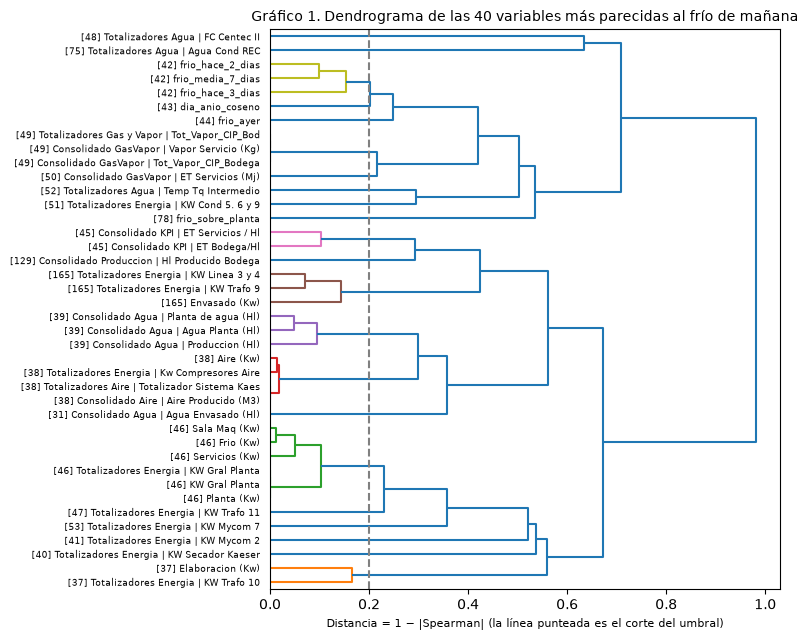

In [5]:
CANTIDAD_EN_EL_GRAFICO = 40
mas_parecidas = parecido.abs().sort_values(ascending=False).head(CANTIDAD_EN_EL_GRAFICO).index.tolist()

sub_corr = correlaciones.loc[mas_parecidas, mas_parecidas]
distancia = 1 - sub_corr.abs().to_numpy()
np.fill_diagonal(distancia, 0.0)
distancia = (distancia + distancia.T) / 2
from scipy.spatial.distance import squareform
enlace_sub = linkage(squareform(distancia, checks=False), method="complete")

etiquetas = [f"[{grupos[c]}] {c[:45]}" for c in mas_parecidas]
fig, ax = plt.subplots(figsize=(8, 6.5))
dendrograma = dendrogram(enlace_sub, labels=etiquetas, orientation="right", color_threshold=1 - UMBRAL_CORRELACION, ax=ax, leaf_font_size=6.5)
ax.axvline(1 - UMBRAL_CORRELACION, linestyle="--", color="gray")
ax.set_xlabel("Distancia = 1 − |Spearman| (la línea punteada es el corte del umbral)")
ax.set_title(f"Gráfico 1. Dendrograma de las {CANTIDAD_EN_EL_GRAFICO} variables más parecidas al frío de mañana", fontsize=10)
ax.set_xlabel(ax.get_xlabel(), fontsize=8)
plt.tight_layout(); plt.show()

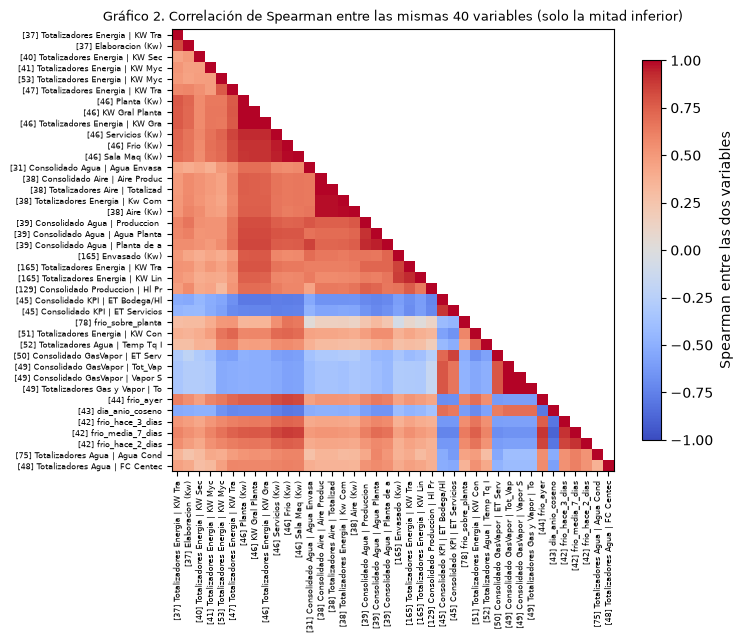

In [6]:
orden = [mas_parecidas[i] for i in dendrograma["leaves"]]       # mismo orden que el dendrograma, de arriba a abajo
fig, ax = plt.subplots(figsize=(7.5, 6.5))
sub = correlaciones.loc[orden, orden].to_numpy()
parte_inferior = np.ma.masked_where(np.triu(np.ones_like(sub, dtype=bool), k=1), sub)   # se oculta lo de arriba de la diagonal (es el espejo)
imagen = ax.imshow(parte_inferior, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(orden))); ax.set_yticks(range(len(orden)))
ax.set_xticklabels([f"[{grupos[c]}] {c[:30]}" for c in orden], rotation=90, fontsize=6)
ax.set_yticklabels([f"[{grupos[c]}] {c[:30]}" for c in orden], fontsize=6)
fig.colorbar(imagen, ax=ax, label="Spearman entre las dos variables", shrink=0.8)
ax.set_title(f"Gráfico 2. Correlación de Spearman entre las mismas {CANTIDAD_EN_EL_GRAFICO} variables (solo la mitad inferior)", fontsize=9)
plt.tight_layout(); plt.show()

La matriz es simétrica (la correlación de A con B es igual a la de B con A), por eso se dibuja solo la mitad inferior. En ella, los bloques rojos (o azules fuertes, si el signo es negativo) sobre la diagonal son variables que se mueven juntas: son los grupos del dendrograma. Mirando solo estas cuarenta se ve que las más parecidas al objetivo forman varios bloques, y que dentro de cada uno alcanza con quedarse con una.

## 6. Método 1: la mejor variable de cada grupo

Con los grupos de la sección 4, de cada grupo se toma la variable de mayor parecido (en valor absoluto) con el frío de mañana, y de esas representantes se quedan las diez con mayor parecido. La tabla indica a qué grupo pertenece cada una y cuántas variables tiene ese grupo, es decir, a cuántas otras está representando.

In [7]:
base_por_grupos = elegir_por_grupos(parecido, grupos, CANTIDAD_BASE)
tabla_grupos = pd.DataFrame({
    "Variable": base_por_grupos,
    "Spearman con el frío de mañana": parecido[base_por_grupos].to_numpy(),
    "Grupo": grupos[base_por_grupos].to_numpy(),
    "Variables en su grupo": tamanos[grupos[base_por_grupos]].to_numpy()})
print(f"Tabla 5. Método 1: {CANTIDAD_BASE} variables base, la mejor de cada grupo")
display(tabla_simple(tabla_grupos, precision=3))

Tabla 5. Método 1: 10 variables base, la mejor de cada grupo


,Variable,Spearman con el frío de mañana,Grupo,Variables en su grupo
0,Frio (Kw),0.847,46,6
1,frio_media_7_dias,0.834,42,3
2,dia_anio_coseno,-0.801,43,1
3,frio_ayer,0.752,44,1
4,Consolidado KPI | ET Bodega/Hl,-0.722,45,2
5,Totalizadores Energia | KW Trafo 11,0.717,47,1
6,Consolidado Agua | Agua Planta (Hl),0.701,39,3
7,Totalizadores Energia | KW Cond 5. 6 y 9,0.685,51,1
8,Totalizadores Energia | KW Mycom 7,0.634,53,1
9,Totalizadores Energia | KW Trafo 9,0.600,165,4


## 7. Método 2: control con una regla simple

Como segunda prueba se hace lo más directo: se ordenan todas las variables de mayor a menor parecido con el frío de mañana y se van agregando de a una, pero solo si su correlación con cada una de las ya elegidas es menor al umbral. Si el resultado coincide en gran parte con el método 1, la elección es sólida.

In [8]:
base_voraz = elegir_voraz(parecido, correlaciones, CANTIDAD_BASE, UMBRAL_CORRELACION)
tabla_voraz = pd.DataFrame({
    "Variable": base_voraz,
    "Spearman con el frío de mañana": parecido[base_voraz].to_numpy(),
    "Mayor |Spearman| con las ya elegidas": [
        max([abs(correlaciones.loc[v, otra]) for otra in base_voraz[:i]], default=0.0) for i, v in enumerate(base_voraz)]})
print(f"Tabla 6. Método 2: {CANTIDAD_BASE} variables base con la regla del umbral")
display(tabla_simple(tabla_voraz, precision=3))

Tabla 6. Método 2: 10 variables base con la regla del umbral


,Variable,Spearman con el frío de mañana,Mayor |Spearman| con las ya elegidas
0,Frio (Kw),0.847,0.000
1,dia_anio_coseno,-0.801,0.796
2,frio_hace_2_dias,0.731,0.797
3,Consolidado KPI | ET Bodega/Hl,-0.722,0.766
4,Consolidado Agua | Agua Planta (Hl),0.701,0.783
5,Totalizadores Energia | KW Cond 5. 6 y 9,0.685,0.720
6,Totalizadores Energia | KW Mycom 7,0.634,0.713
7,Totalizadores Energia | KW Trafo 9,0.600,0.720
8,Consolidado GasVapor | ET Servicios (Mj),-0.600,0.714
9,Totalizadores Energia | KW Mycom 2,0.595,0.681


## 8. Comparación de los dos métodos y controles

La primera tabla indica, para cada variable que aparece en alguna de las dos listas, si la eligió el método 1, el método 2 o ambos. La segunda verifica, para cada lista, cuál es la correlación más alta entre dos de sus variables: si ese valor supera el umbral, la lista todavía contiene variables redundantes.

In [9]:
todas = list(dict.fromkeys(base_por_grupos + base_voraz))
comparacion = pd.DataFrame({
    "Variable": todas,
    "Método 1 (grupos)": ["sí" if v in base_por_grupos else "no" for v in todas],
    "Método 2 (regla)": ["sí" if v in base_voraz else "no" for v in todas],
    "Spearman con el frío de mañana": parecido[todas].to_numpy()})
print("Tabla 7. Qué variables eligió cada método")
display(tabla_simple(comparacion, precision=3))

def mayor_entre_pares(lista):
    sub = correlaciones.loc[lista, lista].abs().to_numpy().copy()
    np.fill_diagonal(sub, 0.0)
    return sub.max()

controles = pd.DataFrame({
    "Variables en común": [len(set(base_por_grupos) & set(base_voraz))] * 2,
    "Mayor |Spearman| entre dos de sus variables": [mayor_entre_pares(base_por_grupos), mayor_entre_pares(base_voraz)]},
    index=["Método 1 (grupos)", "Método 2 (regla)"]).rename_axis("Lista").reset_index()
print(f"Tabla 8. Controles: redundancia dentro de cada lista (umbral {UMBRAL_CORRELACION})")
display(tabla_simple(controles, precision=3))

reglas_solo_train = {"ok": X.index.equals(entrenamiento.index) and len(entrenamiento) == 848,
                     "sin_vacios_en_matriz": not correlaciones.isna().any().any()}
print("Todo calculado con las 848 filas de entrenamiento y sin vacíos en la matriz:", all(reglas_solo_train.values()))

Tabla 7. Qué variables eligió cada método


,Variable,Método 1 (grupos),Método 2 (regla),Spearman con el frío de mañana
0,Frio (Kw),sí,sí,0.847
1,frio_media_7_dias,sí,no,0.834
2,dia_anio_coseno,sí,sí,-0.801
3,frio_ayer,sí,no,0.752
4,Consolidado KPI | ET Bodega/Hl,sí,sí,-0.722
5,Totalizadores Energia | KW Trafo 11,sí,no,0.717
6,Consolidado Agua | Agua Planta (Hl),sí,sí,0.701
7,Totalizadores Energia | KW Cond 5. 6 y 9,sí,sí,0.685
8,Totalizadores Energia | KW Mycom 7,sí,sí,0.634
9,Totalizadores Energia | KW Trafo 9,sí,sí,0.600


Tabla 8. Controles: redundancia dentro de cada lista (umbral 0.8)


,Lista,Variables en común,Mayor |Spearman| entre dos de sus variables
0,Método 1 (grupos),7,0.898
1,Método 2 (regla),7,0.797


Todo calculado con las 848 filas de entrenamiento y sin vacíos en la matriz: True


## 9. Aplicación de `PolynomialFeatures`

Con la lista elegida se aprenden las reglas (solo con entrenamiento) y se crean las interacciones. `PolynomialFeatures` con grado 2 y `interaction_only=True` multiplica cada par de variables base una sola vez y no agrega los cuadrados, así que diez variables dan cuarenta y cinco columnas nuevas. Esta herramienta no acepta valores vacíos, por lo que la función los calcula con ceros y después anula todo producto en que alguno de los dos factores estaba vacío: un producto con un dato que falta no se puede conocer y no debe valer cero. La primera tabla controla que las reglas aprendidas coinciden con la lista del método 2. La segunda muestra, con tres días de ejemplo, cómo se arma una interacción a partir de sus dos factores.

In [10]:
reglas_interacciones = aprender_reglas_de_interacciones(entrenamiento)          # solo con entrenamiento
tabla_final = crear_interacciones(tabla_con_variables, reglas_interacciones)     # se aplica a la tabla completa
nuevas = nombres_de_interacciones(reglas_interacciones["variables_base"])
tr_i, va_i, te_i = dividir_por_fecha(tabla_final)

coincide = reglas_interacciones["variables_base"] == base_voraz
print("Tabla 9. Variables base aprendidas (¿coinciden con la lista del método 2? ->", coincide, ")")
display(tabla_simple(pd.DataFrame({"Variable base": reglas_interacciones["variables_base"]}), precision=0))

un_par = nuevas[0]
factor_a, factor_b = un_par.split(" x ")
ejemplo = tr_i[[factor_a, factor_b, un_par]].dropna().sample(3, random_state=42).sort_index()   # tres días al azar (SEMILLA = 42)
print(f"Tabla 10. Ejemplo de tres días de entrenamiento con valor: «{un_par}» es el producto de sus dos factores")
display(tabla_simple(ejemplo.reset_index(drop=True), precision=2))

Tabla 9. Variables base aprendidas (¿coinciden con la lista del método 2? -> True )


,Variable base
0,Frio (Kw)
1,dia_anio_coseno
2,frio_hace_2_dias
3,Consolidado KPI | ET Bodega/Hl
4,Consolidado Agua | Agua Planta (Hl)
5,Totalizadores Energia | KW Cond 5. 6 y 9
6,Totalizadores Energia | KW Mycom 7
7,Totalizadores Energia | KW Trafo 9
8,Consolidado GasVapor | ET Servicios (Mj)
9,Totalizadores Energia | KW Mycom 2


Tabla 10. Ejemplo de tres días de entrenamiento con valor: «Frio (Kw) x dia_anio_coseno» es el producto de sus dos factores


,Frio (Kw),dia_anio_coseno,Frio (Kw) x dia_anio_coseno
0,33954.00,-0.32,-10728.17
1,22594.00,0.24,5506.83
2,15643.00,0.27,4267.59


## 10. Controles y vacíos de las interacciones

La primera tabla cuenta cuántos días quedan vacíos en las interacciones de cada tramo: un producto queda vacío si alguna de las dos variables que lo forman está vacía ese día. La segunda tabla reúne los controles, que deben dar verdadero: la cantidad de columnas nuevas, que las filas y las columnas originales no cambian, que ninguna interacción vale infinito, que no hay cuadrados y que una interacción revisada a mano coincide.

In [11]:
vacios_i = pd.DataFrame({"Entrenamiento": [tr_i[nuevas].isna().sum().min(), tr_i[nuevas].isna().sum().max()],
                         "Validación": [va_i[nuevas].isna().sum().min(), va_i[nuevas].isna().sum().max()],
                         "Prueba": [te_i[nuevas].isna().sum().min(), te_i[nuevas].isna().sum().max()]},
                        index=["Menor cantidad de días vacíos", "Mayor cantidad de días vacíos"]).rename_axis("Entre las interacciones").reset_index()
print(f"Tabla 11. Días vacíos por interacción y por tramo (entrenamiento {len(tr_i)} días, validación {len(va_i)}, prueba {len(te_i)})")
display(tabla_simple(vacios_i, precision=0))

fila = tr_i.index[tr_i[[factor_a, factor_b]].notna().all(axis=1)][0]
controles_i = {
    "Se agregan 45 columnas": len(nuevas) == 45 and tabla_final.shape[1] == tabla_con_variables.shape[1] + 45,
    "Mismas filas e índice": tabla_final.index.equals(tabla_con_variables.index),
    "Las columnas originales no cambian": tabla_final[tabla_con_variables.columns].equals(tabla_con_variables),
    "Las nuevas se agregan al final y sin repetirse": list(tabla_final.columns) == list(tabla_con_variables.columns) + nuevas and tabla_final.columns.is_unique,
    "Ninguna interacción vale infinito": not np.isinf(tabla_final[nuevas].to_numpy(dtype=float)).any(),
    "No hay cuadrados (ninguna variable multiplicada por sí misma)": all(a != b for a, b in (n.split(" x ") for n in nuevas)),
    "Una fila revisada a mano: producto = factor A por factor B": bool(np.isclose(tabla_final.loc[fila, un_par], tabla_final.loc[fila, factor_a] * tabla_final.loc[fila, factor_b])),
    "Las reglas salen solo de entrenamiento (recalcular da lo mismo)": aprender_reglas_de_interacciones(entrenamiento) == reglas_interacciones,
}
print("Tabla 12. Controles (todos deben dar True)")
display(tabla_simple(pd.DataFrame({"Resultado": controles_i}).rename_axis("Control").reset_index()))

Tabla 11. Días vacíos por interacción y por tramo (entrenamiento 848 días, validación 182, prueba 182)


,Entre las interacciones,Entrenamiento,Validación,Prueba
0,Menor cantidad de días vacíos,2,3,1
1,Mayor cantidad de días vacíos,36,16,11


Tabla 12. Controles (todos deben dar True)


,Control,Resultado
0,Se agregan 45 columnas,True
1,Mismas filas e índice,True
2,Las columnas originales no cambian,True
3,Las nuevas se agregan al final y sin repetirse,True
4,Ninguna interacción vale infinito,True
5,No hay cuadrados (ninguna variable multiplicada por sí misma),True
6,Una fila revisada a mano: producto = factor A por factor B,True
7,Las reglas salen solo de entrenamiento (recalcular da lo mismo),True


## 11. Conclusión

Los dos métodos coinciden en una parte de la lista, pero no son equivalentes. El agrupamiento con enlace completo asegura que dentro de un grupo todos los pares se parecen, pero no que dos variables de grupos distintos se parezcan poco: por eso la lista del método 1 puede incluir pares con correlación mayor al umbral, como lo muestra la tabla 8. Los casos más claros son el frío de hoy, el frío de ayer y el promedio de siete días, que cayeron en grupos distintos y aun así se parecen mucho entre sí. La regla del método 2 sí garantiza que ningún par de su lista supere el umbral, y para eso deja afuera esas variantes del frío y las reemplaza por otras que aportan algo distinto. Para las interacciones importa más la segunda propiedad, porque multiplicar dos variables casi iguales equivale a repetir una sola. Por eso se elige la lista del método 2 como variables base: es la única de las dos en la que ningún par de variables supera el umbral de correlación entre sí, mientras que la del método 1 deja pares redundantes que luego se multiplicarían entre sí sin aportar información nueva. Se mantiene el método 1 en el notebook porque permite ver los grupos de variables que dicen lo mismo y porque su comparación con el método 2 respalda la decisión. Con esa lista se aplicó `PolynomialFeatures` (grado 2, solo productos), que agrega cuarenta y cinco columnas, y los controles de la sección 10 dan verdadero. Lo que sigue es integrar las variables temporales, las razones y las interacciones en una sola función y pasar a la selección de variables.